# Lab Exercise 8 
## Dairy Cattle Growth, Health & Feed Management
**Dataset:** [Kaggle Livestock Growth and Weight Prediction](https://www.kaggle.com/datasets/muhammedfakl/livestock-growth-and-weight-prediction-dataset)

In [15]:
# Install if needed: %pip install pandas numpy matplotlib kagglehub
import pandas as pd, numpy as np, matplotlib.pyplot as plt, kagglehub
from pathlib import Path

plt.rcParams.update({"figure.facecolor":"white","axes.facecolor":"white","axes.grid":True,"grid.alpha":0.25})
path = kagglehub.dataset_download("muhammedfakl/livestock-growth-and-weight-prediction-dataset")
csvs = list(Path(path).rglob("*.csv"))
if not csvs: raise FileNotFoundError("No CSV found in Kaggle dataset")
df = pd.read_csv(csvs[0])
print("Shape:",df.shape,"\\nColumns:",df.columns.tolist())
print("\\nData types:\\n",df.dtypes)
print("\\nMissing values:\\n",df.isna().sum())
df.info()
display(df.head())

# Convert likely measurements to numeric, if present
for c in ["birth_weight_kg","weight_3m_kg","weight_12m_kg","withers_height_cm","chest_girth_cm","colostrum_liters_first_week"]:
    if c in df: df[c]=pd.to_numeric(df[c],errors="coerce")
numeric=df.select_dtypes(include="number").columns.tolist()
categorical=df.select_dtypes(include=["object","string","category"]).columns.tolist()
plot_df=df.copy()
for c in numeric: plot_df[c]=plot_df[c].fillna(plot_df[c].median())
print("Numeric columns:",numeric,"\\nCategorical columns:",categorical)

Shape: (2000, 15) \nColumns: ['animal_id', 'breed', 'sex', 'birth_weight_kg', 'withers_height_cm', 'chest_girth_cm', 'body_length_cm', 'colostrum_liters_first_week', 'early_health_score', 'ration_type', 'daily_dry_matter_intake_kg', 'disease_history_first_3m', 'weight_3m_kg', 'weight_6m_kg', 'weight_12m_kg']
\nData types:\n animal_id                          str
breed                              str
sex                                str
birth_weight_kg                float64
withers_height_cm              float64
chest_girth_cm                 float64
body_length_cm                 float64
colostrum_liters_first_week    float64
early_health_score               int64
ration_type                        str
daily_dry_matter_intake_kg     float64
disease_history_first_3m         int64
weight_3m_kg                   float64
weight_6m_kg                   float64
weight_12m_kg                  float64
dtype: object
\nMissing values:\n animal_id                      0
breed                 

,animal_id,breed,sex,birth_weight_kg,withers_height_cm,chest_girth_cm,body_length_cm,colostrum_liters_first_week,early_health_score,ration_type,daily_dry_matter_intake_kg,disease_history_first_3m,weight_3m_kg,weight_6m_kg,weight_12m_kg
0,ANM-00001,Hereford,Female,31.1,74.4,77.1,61.6,24.8,5,high_energy,5.22,0,105.3,205.1,344.3
1,ANM-00002,Jersey,Male,40.8,70.3,78.6,59.7,8.6,4,standard,4.67,0,88.0,177.4,282.6
2,ANM-00003,Limuzin,Female,41.3,77.7,87.9,76.0,25.0,3,high_protein,5.52,1,109.9,188.2,296.6
3,ANM-00004,Angus,Female,33.1,75.8,92.0,85.7,25.0,5,standard,5.44,0,117.4,213.3,336.9
4,ANM-00005,Holstein,Male,39.1,79.1,87.0,73.8,22.2,4,high_energy,6.67,0,129.4,259.2,465.5


Numeric columns: ['birth_weight_kg', 'withers_height_cm', 'chest_girth_cm', 'body_length_cm', 'colostrum_liters_first_week', 'early_health_score', 'daily_dry_matter_intake_kg', 'disease_history_first_3m', 'weight_3m_kg', 'weight_6m_kg', 'weight_12m_kg'] \nCategorical columns: ['animal_id', 'breed', 'sex', 'ration_type']


## 1. Bar plot — cattle count by breed

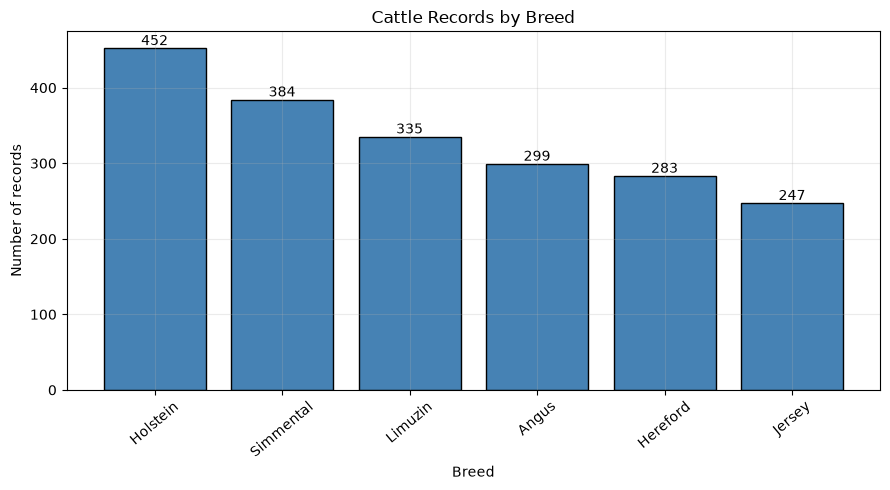

Observations: 6 breeds; most common=Holstein (452); least common=Jersey (247).


In [16]:
if "breed" in plot_df:
    counts=plot_df["breed"].dropna().value_counts()
    fig,ax=plt.subplots(figsize=(9,5)); bars=ax.bar(counts.index.astype(str),counts.values,color="steelblue",edgecolor="black")
    ax.set(title="Cattle Records by Breed",xlabel="Breed",ylabel="Number of records"); ax.tick_params(axis="x",rotation=40); ax.bar_label(bars); plt.tight_layout(); plt.show()
    print(f"Observations: {len(counts)} breeds; most common={counts.index[0]} ({counts.iloc[0]}); least common={counts.index[-1]} ({counts.iloc[-1]}).")
else: print("No breed column; available categories:",categorical)

## 2. Line chart — average weight across growth stages

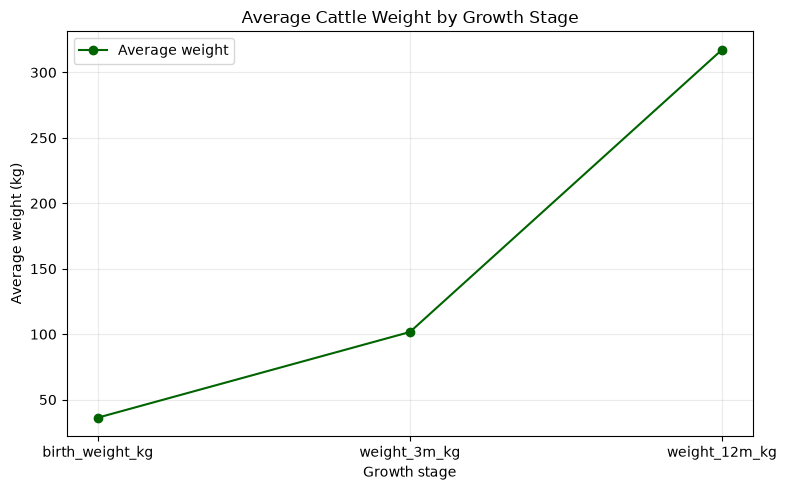

Observations: points show stage averages; slope shows growth direction; first-to-last change = 281.08 kg


In [17]:
growth=[c for c in ["birth_weight_kg","weight_3m_kg","weight_12m_kg"] if c in plot_df]
if growth:
    avg=plot_df[growth].mean(); fig,ax=plt.subplots(figsize=(8,5))
    ax.plot(avg.index,avg.values,marker="o",color="darkgreen",label="Average weight")
    ax.set(title="Average Cattle Weight by Growth Stage",xlabel="Growth stage",ylabel="Average weight (kg)"); ax.legend(); plt.tight_layout(); plt.show()
    print("Observations: points show stage averages; slope shows growth direction; first-to-last change =",round(avg.iloc[-1]-avg.iloc[0],2),"kg")
else: print("Growth weight columns not found.")

## 3. Histogram — weight frequency distribution

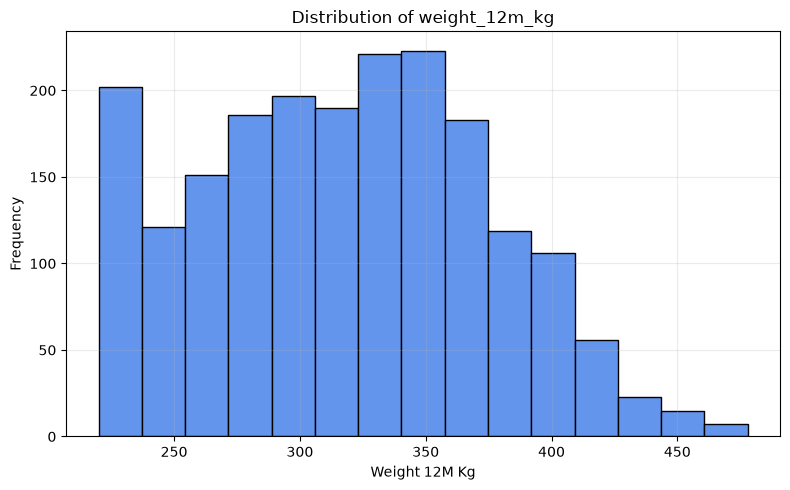

Observations: mean=317.33; median=319.70; range=220.00–477.90.


In [18]:
w="weight_12m_kg" if "weight_12m_kg" in plot_df else (numeric[0] if numeric else None)
if w:
    v=plot_df[w].dropna(); fig,ax=plt.subplots(figsize=(8,5)); ax.hist(v,bins=15,color="cornflowerblue",edgecolor="black")
    ax.set(title=f"Distribution of {w}",xlabel=w.replace("_"," ").title(),ylabel="Frequency"); plt.tight_layout(); plt.show()
    print(f"Observations: mean={v.mean():.2f}; median={v.median():.2f}; range={v.min():.2f}–{v.max():.2f}.")
else: print("No numeric column available.")

## 4. Box plot — median, quartiles, and outliers

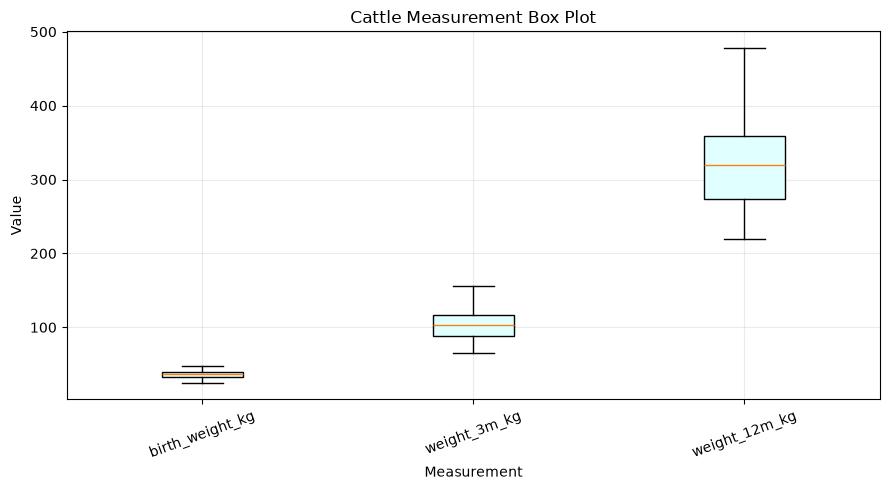

Observations:
1. The center line represents the median.
2. The box represents the interquartile range (Q1–Q3).
3. Points beyond the whiskers may indicate outliers.


In [19]:

cols = [
    c for c in ["birth_weight_kg", "weight_3m_kg", "weight_12m_kg"]
    if c in plot_df
] or numeric[:3]

if cols:
    fig, ax = plt.subplots(figsize=(9, 5))

    bp = ax.boxplot(
        [plot_df[c].dropna() for c in cols],
        patch_artist=True,
        tick_labels=cols  # Updated parameter
    )

    for box in bp["boxes"]:
        box.set_facecolor("lightcyan")

    ax.set_title("Cattle Measurement Box Plot")
    ax.set_xlabel("Measurement")
    ax.set_ylabel("Value")
    ax.tick_params(axis="x", rotation=20)

    plt.tight_layout()
    plt.show()

    print("Observations:")
    print("1. The center line represents the median.")
    print("2. The box represents the interquartile range (Q1–Q3).")
    print("3. Points beyond the whiskers may indicate outliers.")
else:
    print("No numeric attributes available.")


## 5. Pie chart — breed percentage distribution

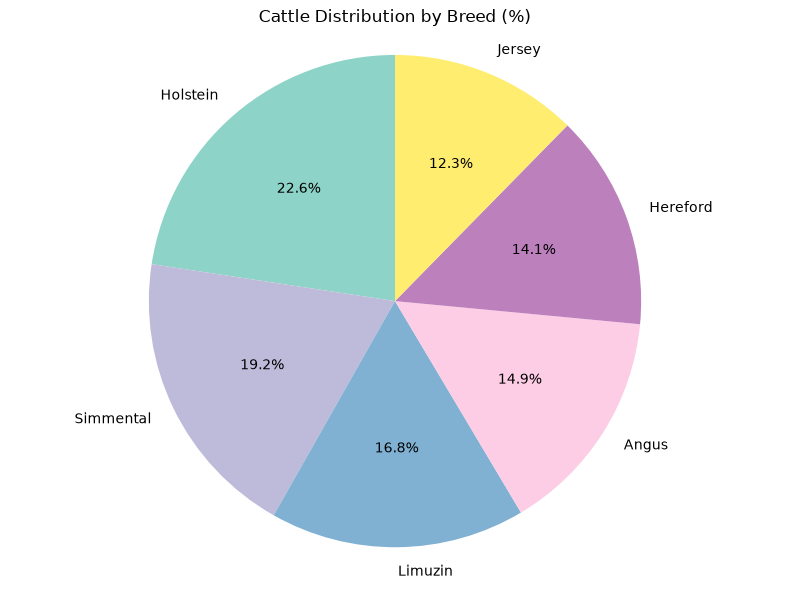

Observations: slices show breed proportions; largest slice is Holstein ; smaller breeds are grouped as Other when needed.


In [20]:
if "breed" in plot_df:
    counts=plot_df["breed"].dropna().value_counts()
    pie=counts.copy()
    if len(counts)>6: pie=counts.iloc[:5].copy(); pie.loc["Other breeds"]=counts.iloc[5:].sum()
    fig,ax=plt.subplots(figsize=(8,6)); ax.pie(pie.values,labels=pie.index.astype(str),autopct="%1.1f%%",startangle=90,colors=plt.cm.Set3(np.linspace(0,1,len(pie))))
    ax.set_title("Cattle Distribution by Breed (%)"); ax.axis("equal"); plt.tight_layout(); plt.show()
    print("Observations: slices show breed proportions; largest slice is",pie.index[0],"; smaller breeds are grouped as Other when needed.")
else: print("No breed column.")

## 6. Scatter plot — birth weight vs 12-month weight

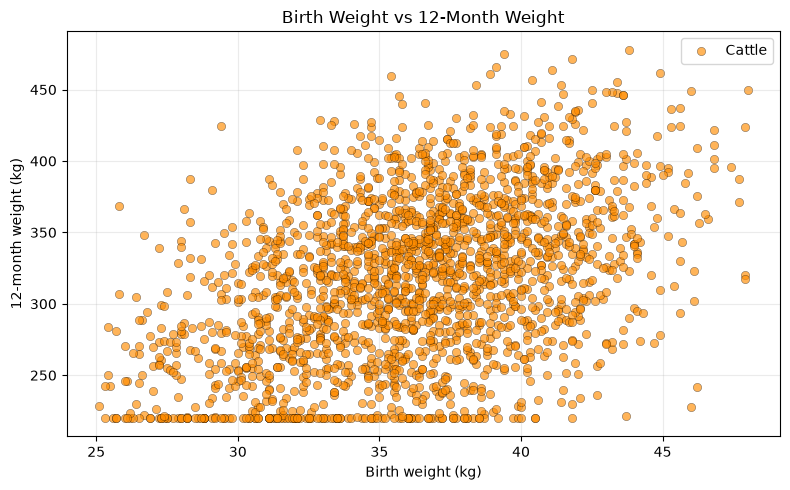

Observations: each dot is a cattle record; upward pattern indicates positive association; correlation = 0.43


In [21]:
if {"birth_weight_kg","weight_12m_kg"}.issubset(plot_df.columns):
    x=plot_df["birth_weight_kg"]; y=plot_df["weight_12m_kg"]; ok=x.notna()&y.notna()
    fig,ax=plt.subplots(figsize=(8,5)); ax.scatter(x[ok],y[ok],alpha=.65,color="darkorange",edgecolors="black",linewidths=.3,label="Cattle")
    ax.set(title="Birth Weight vs 12-Month Weight",xlabel="Birth weight (kg)",ylabel="12-month weight (kg)"); ax.legend(); plt.tight_layout(); plt.show()
    print("Observations: each dot is a cattle record; upward pattern indicates positive association; correlation =",round(x[ok].corr(y[ok]),3))
else: print("Required weight columns not found.")

## 7. Pair plot — pairwise numerical relationships (Matplotlib only)

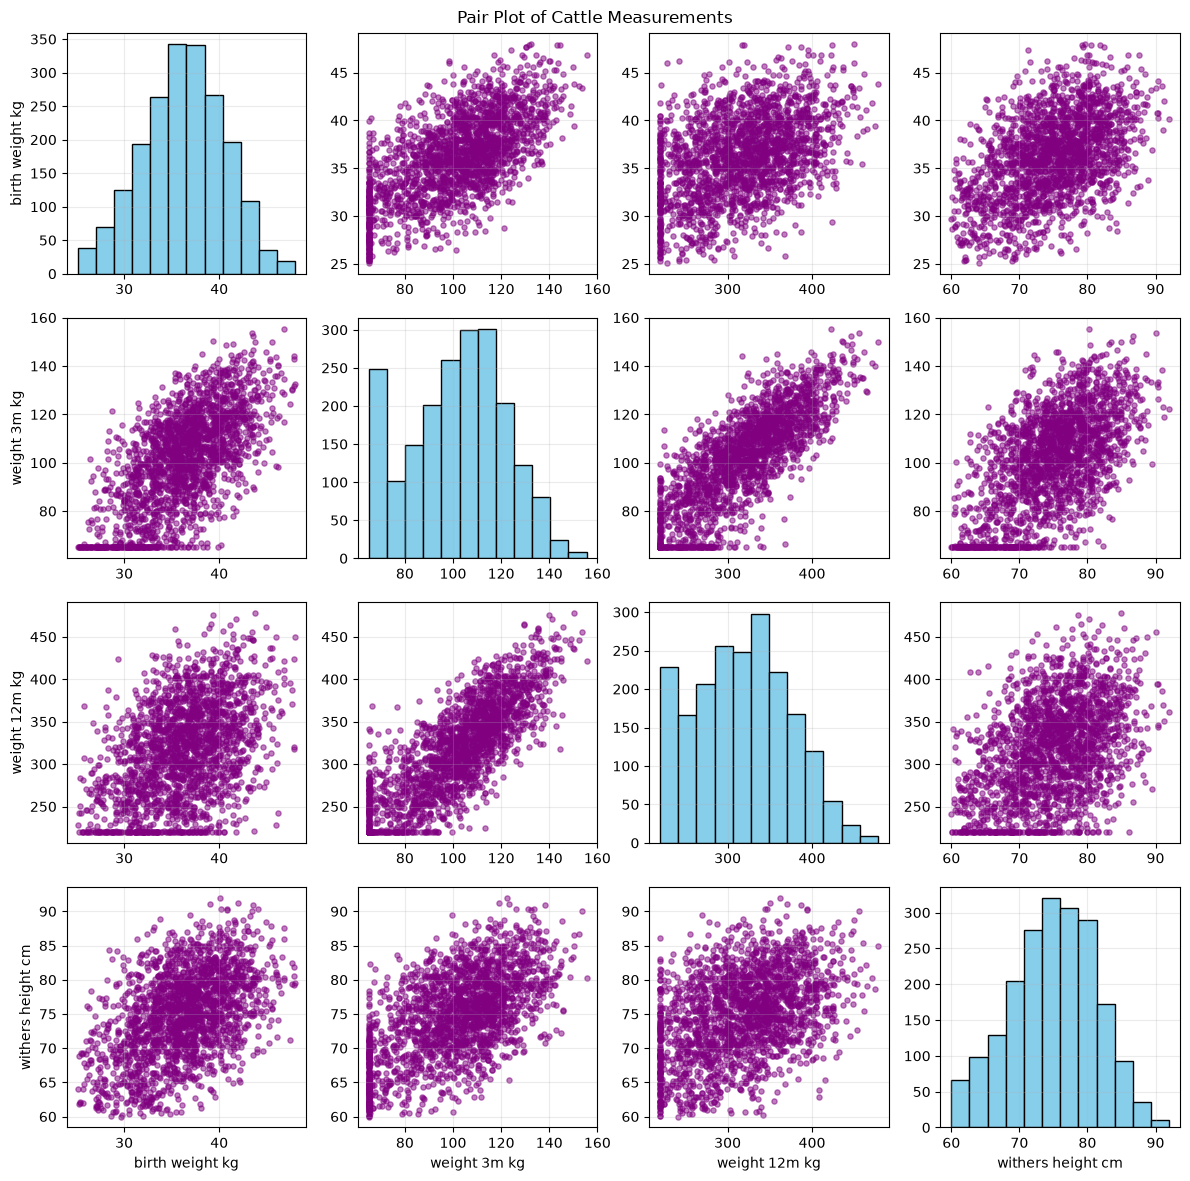

Observations: diagonal panels show distributions; off-diagonal panels show relationships; clusters/trends/outliers can be observed.


In [22]:
pair=[c for c in ["birth_weight_kg","weight_3m_kg","weight_12m_kg","withers_height_cm","chest_girth_cm"] if c in plot_df][:4]
if len(pair)>=2:
    d=plot_df[pair].dropna(); n=len(pair); fig,axes=plt.subplots(n,n,figsize=(3*n,3*n))
    for i,a in enumerate(pair):
        for j,b in enumerate(pair):
            ax=axes[i,j]
            if i==j: ax.hist(d[b],bins=12,color="skyblue",edgecolor="black")
            else: ax.scatter(d[b],d[a],s=14,alpha=.5,color="purple")
            if i==n-1: ax.set_xlabel(b.replace("_"," "))
            if j==0: ax.set_ylabel(a.replace("_"," "))
    fig.suptitle("Pair Plot of Cattle Measurements"); plt.tight_layout(); plt.show()
    print("Observations: diagonal panels show distributions; off-diagonal panels show relationships; clusters/trends/outliers can be observed.")
else: print("Need at least two numeric columns for pair plot.")

## 8. Violin plot

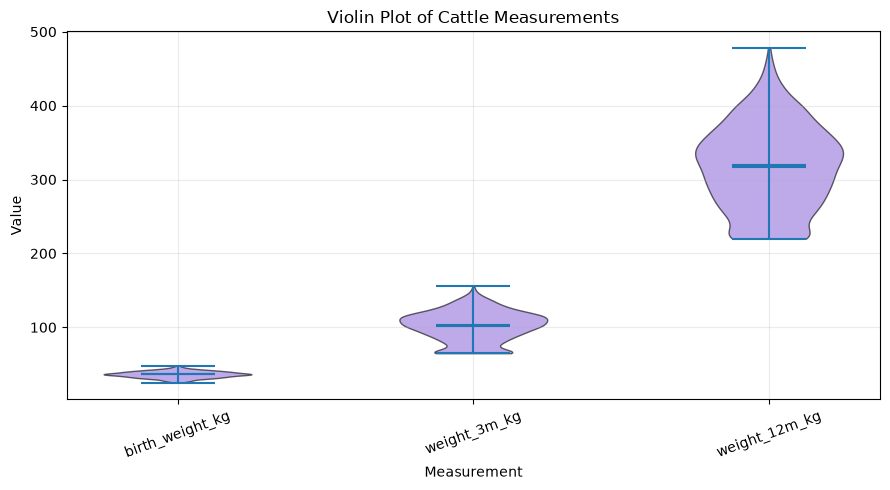

Observations: wider regions indicate higher density; median/mean markers show central values; shapes compare distributions.


In [23]:
vcols=[c for c in ["birth_weight_kg","weight_3m_kg","weight_12m_kg"] if c in plot_df] or numeric[:3]
if vcols:
    fig,ax=plt.subplots(figsize=(9,5)); parts=ax.violinplot([plot_df[c].dropna() for c in vcols],showmedians=True,showmeans=True)
    for body in parts["bodies"]: body.set_facecolor("mediumpurple"); body.set_edgecolor("black"); body.set_alpha(.6)
    ax.set_xticks(range(1,len(vcols)+1)); ax.set_xticklabels(vcols,rotation=20); ax.set(title="Violin Plot of Cattle Measurements",xlabel="Measurement",ylabel="Value"); plt.tight_layout(); plt.show()
    print("Observations: wider regions indicate higher density; median/mean markers show central values; shapes compare distributions.")
else: print("No numeric columns.")